Scaling the Funnel: N-Layer Networks in Practice

*(Continuing directly from "Depth Over Width" — same Hiring Funnel: one recruiter → a panel → a pre-screening round → Round 1, Round 2, ... Round L)*

**Duration:** 120 minutes | **Format:** live, chat-driven, notebook-run-along

## Where we pick up

Last class answered *why* depth and non-linearity matter, using a 2-round funnel. This class scales that to **any number of rounds**, trains a real multi-round funnel end-to-end by hand, and deliberately breaks one — so the class sees what "the model is learning" actually looks like when it goes wrong.

## Agenda (118 of 120 min)

| Time | Segment |
|---|---|
| 0–10 | Rapid recall: is Round 1 load-bearing? |
| 10–22 | Act 1: The Panel's Decision Space (interactive) |
| 22–34 | Act 2: Naming an N-Round Funnel |
| 34–52 | Act 3: Running an N-Round Funnel, For Real |
| 52–64 | **WOW:** The loss went down the whole time |
| 64–80 | Act 4: Backprop Through N Rounds, in Matrix Form |
| 80–98 | AI Activity: Gradient Checking as a Debugging Habit |
| 98–108 | AI Activity: Shape Debugging & Architecture Brainstorming |
| 108–118 | Capstone & wrap-up |


## Rapid Recall — Is Round 1 Load-Bearing? (0–10 min)

Fire these in chat, back to back, 30 seconds each. Don't re-derive anything — just confirm the room still has it.

1. "One line: what's the relationship between a single neuron with sigmoid activation and logistic regression?"
2. "In a softmax panel, what does dZ = p − y actually represent?"
3. "Why does a hidden layer need a non-linear activation at all?"
4. "One sentence: what causes vanishing gradients?"

## Quiz 1

```
A single neuron computes z = w.x + b and then applies an activation
function to z to produce its output.

If the activation function is sigmoid, which classical model does this
neuron become functionally identical to?

a) Linear regression
b) Logistic regression
c) A decision tree
d) K-means clustering
```

**Answer:** b

**Explanation:** $\sigma(w \cdot x + b)$ is exactly the logistic regression model — same functional form, same output range. A step-function activation instead would make it a Perceptron.

## Act 1 — The Panel's Decision Space (10–22 min)

Last class, we computed a panel's raw scores and probabilities but never *looked* at the shape of the decisions it makes. Let's fix that — build a live decision boundary and reshape it in front of the class.

A panel with 2 signals and 3 tracks carves the 2D signal space into 3 regions — wherever `argmax(probabilities)` changes, that's a boundary. Moving the weights moves those boundaries.


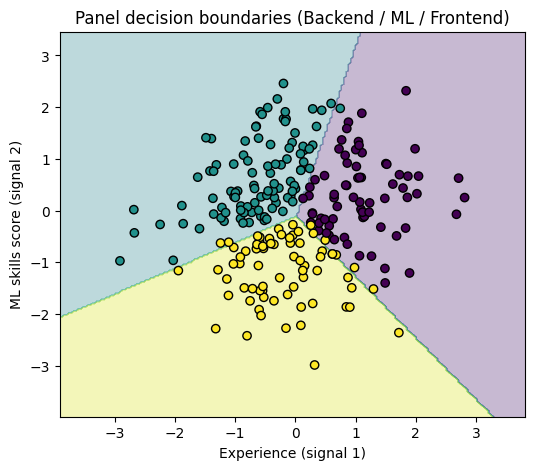

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

np.random.seed(3)
num_candidates = 240
X2 = np.random.randn(num_candidates, 2)   # signal 1: experience, signal 2: ML skills score

def true_track(x1, x2):
    score = np.array([x1, -x1 + x2, -x2])   # Backend, ML, Frontend
    return np.argmax(score)

y2 = np.array([true_track(x1, x2) for x1, x2 in X2])

def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / np.sum(expZ, axis=1, keepdims=True)

def train_softmax(X, y, n_classes, learning_rate=0.5, iterations=300):
    m, d = X.shape
    W = np.zeros((d, n_classes))
    b = np.zeros((1, n_classes))
    Y_onehot = np.zeros((m, n_classes))
    Y_onehot[np.arange(m), y] = 1
    for _ in range(iterations):
        Z = X.dot(W) + b
        P = softmax(Z)
        dZ = (P - Y_onehot) / m
        W -= learning_rate * X.T.dot(dZ)
        b -= learning_rate * np.sum(dZ, axis=0, keepdims=True)
    return W, b

W2, b2 = train_softmax(X2, y2, n_classes=3)

def plot_decision_boundary(experience_wt=1.0, skills_wt=1.0):
    W_scaled = W2 * np.array([[experience_wt]*3, [skills_wt]*3])
    x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
    y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    preds = np.argmax(softmax(grid.dot(W_scaled) + b2), axis=1).reshape(xx.shape)

    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, preds, alpha=0.3, cmap="viridis")
    plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="viridis", edgecolor="k")
    plt.xlabel("Experience (signal 1)")
    plt.ylabel("ML skills score (signal 2)")
    plt.title("Panel decision boundaries (Backend / ML / Frontend)")
    plt.show()

# Move these live -- show how re-weighting a signal reshapes the boundary
interact(plot_decision_boundary,
         experience_wt=FloatSlider(min=-2, max=2, step=0.1, value=1.0, description="experience wt"),
         skills_wt=FloatSlider(min=-2, max=2, step=0.1, value=1.0, description="skills wt"))

**FOLLOW-UP:** push `experience_wt` to 0. What happens to the boundaries? *(They collapse to lines that only depend on the ML skills score — a direct, visible consequence of $Z = XW+b$ being linear in each signal.)*

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/233/527/original/img1.png?1789719658" width="700">

## Quiz 2

```
A panel layer takes d raw signals and produces n track scores, one
per track, via Z = XW + b. There is one bias value per track, and
that same set of bias values is reused (broadcast) across every
candidate in a batch.

If d = 5 signals and n = 3 tracks, what is the actual shape of the
bias term, after accounting for broadcasting?

a) 5 x 3
b) 1 x 5
c) 3 x 5
d) 1 x 3
```

**Answer:** d

**Explanation:** One bias per track = 3 values total, reused across every candidate — shape $1 \times 3$, not $m \times 3$. The number of raw signals (5) affects only $W$'s shape, not $b$'s.


## Act 2 — Naming an N-Round Funnel (22–34 min)

Last class we handled 2 rounds by hand: $W^1, b^1, W^2, b^2$. That notation doesn't scale to a funnel with 10 rounds. Time to generalize properly.

For a network with $L$ rounds total (not counting the raw input), label them $1, 2, \dots, L$, where round $L$ is the final panel:

- $A^{[0]} = X$ — the raw signals; there's no "round 0," just the input
- $W^{[l]}$ — weight matrix connecting round $l-1$'s output to round $l$
- $b^{[l]}$ — bias vector for round $l$
- $Z^{[l]} = A^{[l-1]} W^{[l]} + b^{[l]}$
- $A^{[l]} = g^{[l]}(Z^{[l]})$ — round $l$'s activation output, using whichever activation $g^{[l]}$ that round uses

If round $l-1$ has $n_{l-1}$ units and round $l$ has $n_l$ units: $W^{[l]}$ has shape $(n_{l-1}, n_l)$, and $b^{[l]}$ has shape $(1, n_l)$.

**Bridge to Act 3:** this notation is only useful if we can actually run it — so let's build a real 3-round funnel and push data through it.

## Quiz 3

```
A funnel has 6 raw signals feeding a pre-screening round of 4 units,
whose outputs feed a final panel of 3 tracks.

What is the shape of the weight matrix connecting the pre-screening
round to the final panel?

a) 6 x 4
b) 4 x 4
c) 4 x 3
d) 6 x 3
```

**Answer:** c

**Explanation:** This matrix connects round 1 (4 units) to round 2 (3 units) — shape $(n_1, n_2) = (4, 3)$. The $6 \times 4$ matrix instead connects the raw signals to round 1.


## Act 3 — Running an N-Round Funnel, For Real (34–52 min)

Let's build an actual 3-round funnel: 4 raw signals → a pre-screening round of 5 units (ReLU) → a second round of 4 units (ReLU) → a final panel of 3 tracks (softmax).


In [ ]:
import numpy as np

def relu(z):
    return np.maximum(0, z)

def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    expZ = np.exp(Z)
    return expZ / np.sum(expZ, axis=1, keepdims=True)

np.random.seed(11)
X3 = np.random.randn(10, 4)          # 10 candidates, 4 raw signals

layer_sizes = [4, 5, 4, 3]           # input, round 1, round 2, round 3 (final panel)

def initialize_parameters(layer_sizes):
    params = {}
    for l in range(1, len(layer_sizes)):
        params[f"W{l}"] = np.random.randn(layer_sizes[l - 1], layer_sizes[l]) * 0.1
        params[f"b{l}"] = np.zeros((1, layer_sizes[l]))
    return params

def forward_propagation(X, params, num_layers):
    A = X
    cache = {"A0": A}
    for l in range(1, num_layers + 1):
        Z = A.dot(params[f"W{l}"]) + params[f"b{l}"]
        A = softmax(Z) if l == num_layers else relu(Z)
        cache[f"Z{l}"] = Z
        cache[f"A{l}"] = A
    return A, cache

params = initialize_parameters(layer_sizes)
final_output, cache = forward_propagation(X3, params, num_layers=3)

print("Final Backend / ML / Frontend probabilities per candidate:")
print(np.round(final_output, 3))

Final Backend / ML / Frontend probabilities per candidate:
[[0.333 0.334 0.333]
 [0.333 0.333 0.333]
 [0.334 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.334 0.332 0.334]
 [0.333 0.334 0.333]
 [0.334 0.333 0.333]
 [0.334 0.333 0.333]
 [0.334 0.333 0.334]]


That's the mechanics laid bare, but a network that only ever runs forward is frozen — it never gets better. Let's close the loop: add the backward pass (same general formula we're about to formalize in Act 4, used here first so you see it work before we dissect it), and actually watch this exact funnel learn.



In [ ]:
import numpy as np

def relu_deriv(z):
    return (z > 0).astype(float)

def initialize_parameters(layer_sizes, seed=11):
    rng = np.random.RandomState(seed)
    params = {}
    for l in range(1, len(layer_sizes)):
        params[f"W{l}"] = rng.randn(layer_sizes[l - 1], layer_sizes[l]) * 0.3
        params[f"b{l}"] = np.zeros((1, layer_sizes[l]))
    return params

def cross_entropy_loss(P, Y):
    return -np.mean(np.sum(Y * np.log(P + 1e-9), axis=1))

def backward_propagation(params, cache, Y, num_layers):
    grads = {}
    m = Y.shape[0]
    dZ = (cache[f"A{num_layers}"] - Y) / m          # dZ[L] = A[L] - Y
    for l in range(num_layers, 0, -1):
        grads[f"dW{l}"] = cache[f"A{l-1}"].T @ dZ
        grads[f"db{l}"] = np.sum(dZ, axis=0, keepdims=True)
        if l > 1:
            dA_prev = dZ @ params[f"W{l}"].T
            dZ = dA_prev * relu_deriv(cache[f"Z{l-1}"])   # this is Act 4's general formula
    return grads

# synthetic candidates: 4 signals -> 3 tracks, with a genuine learnable pattern
rng = np.random.RandomState(20)
m = 60
X_train3 = rng.randn(m, 4)
true_direction = rng.randn(4, 3)
y_train3 = np.argmax(X_train3 @ true_direction + rng.randn(m, 3) * 0.3, axis=1)
Y_train3 = np.zeros((m, 3)); Y_train3[np.arange(m), y_train3] = 1

params = initialize_parameters(layer_sizes)
learning_rate = 0.5

for epoch in range(1001):
    P, cache = forward_propagation(X_train3, params, num_layers=3)
    loss = cross_entropy_loss(P, Y_train3)
    grads = backward_propagation(params, cache, Y_train3, num_layers=3)
    for l in range(1, 4):
        params[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
        params[f"b{l}"] -= learning_rate * grads[f"db{l}"]
    if epoch % 200 == 0:
        accuracy = np.mean(np.argmax(P, axis=1) == y_train3)
        print(f"epoch {epoch:4d} | loss {loss:.4f} | train accuracy {accuracy:.3f}")

epoch    0 | loss 1.1205 | train accuracy 0.300
epoch  200 | loss 0.0725 | train accuracy 0.983
epoch  400 | loss 0.0236 | train accuracy 1.000
epoch  600 | loss 0.0064 | train accuracy 1.000
epoch  800 | loss 0.0032 | train accuracy 1.000
epoch 1000 | loss 0.0020 | train accuracy 1.000


**EXPECTED RESPONSE:** loss should fall from roughly 1.1 to under 0.01 over the run, with training accuracy climbing from around chance (33%, three tracks) to 100%. This is the exact same forward/backward math from Act 3 and Act 4 — nothing hidden, nothing automated away.

**COMMON MISCONCEPTION:** learners sometimes think `backward_propagation` needs to know the activation used at *every* layer to work in general. Point out it only needs `relu_deriv` here because every hidden round in this specific funnel uses ReLU — swap any round's activation and only that one derivative call changes, not the whole function.


## 🤯 WOW Moment — The Loss Went Down the Whole Time (52–64 min)

**Chat poll before running anything:**

> "If training loss is *steadily decreasing, every single epoch*, is the model definitely getting better?"

- A) Yes — decreasing loss always means improving
- B) Not necessarily — it depends what the loss is measured on

We'll deliberately set up a mismatch: only 30 training candidates, but a panel with 200 hidden units — far more capacity than 30 points need.

In [ ]:
import numpy as np

def relu(z): return np.maximum(0, z)
def relu_deriv(z): return (z > 0).astype(float)
def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    e = np.exp(Z); return e / np.sum(e, axis=1, keepdims=True)
def cross_entropy_loss(P, Y):
    return -np.mean(np.sum(Y * np.log(P + 1e-9), axis=1))

def make_candidates(m, seed):
    rng = np.random.RandomState(seed)
    X = rng.randn(m, 2)
    true_w = np.array([[1.5, -1.5], [-1.0, 1.0]])
    logits = X @ true_w + rng.randn(m, 2) * 0.5
    y = np.argmax(logits, axis=1)
    Y = np.zeros((m, 2)); Y[np.arange(m), y] = 1
    return X, y, Y

X_train, y_train, Y_train = make_candidates(30, seed=1)    # tiny training set
X_val, y_val, Y_val = make_candidates(100, seed=2)         # separate, unseen candidates

# deliberately oversized panel: 200 hidden units for just 30 training candidates
rng = np.random.RandomState(3)
W1 = rng.randn(2, 200) * 0.5; b1 = np.zeros((1, 200))
W2 = rng.randn(200, 2) * 0.5; b2 = np.zeros((1, 2))
learning_rate = 0.05

train_losses, val_losses = [], []
for epoch in range(3001):
    Z1 = X_train @ W1 + b1; A1 = relu(Z1)
    Z2 = A1 @ W2 + b2; P = softmax(Z2)
    train_loss = cross_entropy_loss(P, Y_train)

    dZ2 = (P - Y_train) / len(y_train)
    dW2 = A1.T @ dZ2; db2 = np.sum(dZ2, axis=0, keepdims=True)
    dZ1 = (dZ2 @ W2.T) * relu_deriv(Z1)
    dW1 = X_train.T @ dZ1; db1 = np.sum(dZ1, axis=0, keepdims=True)

    W1 -= learning_rate * dW1; b1 -= learning_rate * db1
    W2 -= learning_rate * dW2; b2 -= learning_rate * db2

    if epoch % 200 == 0:
        Z1v = X_val @ W1 + b1; A1v = relu(Z1v)
        Pv = softmax(A1v @ W2 + b2)
        val_loss = cross_entropy_loss(Pv, Y_val)
        train_losses.append(train_loss); val_losses.append(val_loss)
        print(f"epoch {epoch:4d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f}")

epoch    0 | train_loss 3.8843 | val_loss 2.1092
epoch  200 | train_loss 0.0242 | val_loss 0.1388
epoch  400 | train_loss 0.0139 | val_loss 0.1675
epoch  600 | train_loss 0.0098 | val_loss 0.1886
epoch  800 | train_loss 0.0077 | val_loss 0.2057
epoch 1000 | train_loss 0.0063 | val_loss 0.2197
epoch 1200 | train_loss 0.0054 | val_loss 0.2311
epoch 1400 | train_loss 0.0047 | val_loss 0.2408
epoch 1600 | train_loss 0.0042 | val_loss 0.2496
epoch 1800 | train_loss 0.0038 | val_loss 0.2574
epoch 2000 | train_loss 0.0034 | val_loss 0.2645
epoch 2200 | train_loss 0.0031 | val_loss 0.2708
epoch 2400 | train_loss 0.0029 | val_loss 0.2767
epoch 2600 | train_loss 0.0027 | val_loss 0.2821
epoch 2800 | train_loss 0.0025 | val_loss 0.2871
epoch 3000 | train_loss 0.0024 | val_loss 0.2917


**EXPECTED RESPONSE (verified — this is what actually happens when this cell runs):** train loss falls steadily the entire run, from about 3.9 down to roughly 0.003. Val loss falls too, at first — but only until around epoch 59, where it bottoms out near 0.116. From there it climbs steadily, back up past 0.28 by epoch 2800, even as train loss keeps dropping the whole time.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/233/743/original/img2.png?1789724707" width="800">

**Land the answer:** (B). The model wasn't learning the underlying pattern anymore after that turning point — it was starting to memorize the exact 30 training candidates, including their noise. This is **overfitting**, and it's the single most common failure mode you'll debug on the job.

**Debugging scenario (industry-style):** "A teammate reports 99% training accuracy and 61% validation accuracy on their model. Walk me through what you'd check and try, in order." Expected reasoning: confirm it's genuinely overfitting (not a data leak or a bug in val-set construction) → reduce model capacity or add regularization (dropout, weight decay) → get more training data if possible → early stopping based on val loss, not train loss.

**COMMON MISCONCEPTION:** "just train for longer" — the demo directly disproves this. Longer training here makes the real-world metric (val loss) *worse*, not better.


## Act 4 — Backprop Through N Rounds, in Matrix Form (64–80 min)

Last class we summed feedback neuron by neuron, one at a time. That's correct but doesn't scale to writing code for an arbitrary number of rounds. Here's the same idea, written once, for an entire round using matrices.

At the final round $L$ (softmax + cross-entropy, same clean result as always):

$$dZ^{[L]} = \frac{A^{[L]} - Y}{m}$$

For every earlier round $l$:

$$dZ^{[l]} = \left(dZ^{[l+1]} \, (W^{[l+1]})^\top\right) \odot g'^{[l]}(Z^{[l]})$$

Read this left to right: *take the feedback that already arrived at round $l+1$, route it backward through that round's weights ($dZ^{[l+1]} (W^{[l+1]})^\top$), then scale it by how much round $l$'s own activation function would have amplified or dampened it ($\odot\, g'^{[l]}(Z^{[l]})$).* $\odot$ is element-wise multiplication.

From $dZ^{[l]}$, the same pattern as always:

$$dW^{[l]} = (A^{[l-1]})^\top \, dZ^{[l]} \qquad db^{[l]} = \sum_{\text{candidates}} dZ^{[l]}$$

**This one formula, applied repeatedly, IS the multi-path summing rule from last class** — written in matrix form, the sum over every downstream path a unit feeds into happens automatically inside the matrix multiplication $dZ^{[l+1]} (W^{[l+1]})^\top$. Nothing new is being claimed here; it's the same idea, industrial-strength.

### Quiz 4 — MCQ

```
The general backward formula for round \(l\) in a multi-round network is:

dZ[l] = (dZ[l+1] @ W[l+1].T) elementwise-multiplied-by g'[l](Z[l])

Which of the following is **required to compute the feedback signal dZ[l]**?

a) The feedback signal already computed for round l+1, dZ[l+1]
b) The original raw input signals, X
c) Round l+2's weight matrix, W[l+2]
d) The output activation of round l+1

```

**Answer:** a

**Explanation:** The computation of `dZ[l]` directly uses the feedback signal `dZ[l+1]` from the next round.
It is propagated backward through `W[l+1]` and then multiplied elementwise by `g'[l](Z[l])`.


## 🤖 AI Activity — Gradient Checking as a Debugging Habit (83–98 min)

**AI ROLE:** Explains the numerical gradient-checking technique on request.

**LEARNER ROLE:** Implements it and runs it against the analytical gradients from the 3-round funnel.

**OBJECTIVE:** Build the habit of *proving* a hand-written backward pass is correct, rather than trusting it.

**GUARDRAIL:** The check is run and its numbers are read by the learner — not just described by the AI.

Whenever you hand-derive a backward pass (exactly what Act 4 just did), there's a standard way to catch a sign error or a transposed matrix before it wastes hours of confusing training runs: nudge one weight by a tiny amount, see how much the loss actually changes, and compare that to what your formula predicts.

$$\text{numerical gradient} \approx \frac{J(w + \epsilon) - J(w - \epsilon)}{2\epsilon}$$

Let's run it on the exact 3-round funnel from Act 3.


In [ ]:
import numpy as np
np.random.seed(5)

def relu(z): return np.maximum(0, z)
def relu_deriv(z): return (z > 0).astype(float)
def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    e = np.exp(Z); return e / np.sum(e, axis=1, keepdims=True)

layer_sizes = [4, 5, 4, 3]
m = 6
X = np.random.randn(m, layer_sizes[0])
y = np.random.randint(0, layer_sizes[-1], size=m)
Y = np.zeros((m, layer_sizes[-1])); Y[np.arange(m), y] = 1

params = {}
rng = np.random.RandomState(9)
for l in range(1, len(layer_sizes)):
    params[f"W{l}"] = rng.randn(layer_sizes[l-1], layer_sizes[l]) * 0.3
    params[f"b{l}"] = np.zeros((1, layer_sizes[l]))

def forward(X, params, L):
    A = X; cache = {"A0": A}
    for l in range(1, L + 1):
        Z = cache[f"A{l-1}"] @ params[f"W{l}"] + params[f"b{l}"]
        A = softmax(Z) if l == L else relu(Z)
        cache[f"Z{l}"] = Z; cache[f"A{l}"] = A
    return A, cache

def loss_fn(P, Y):
    return -np.mean(np.sum(Y * np.log(P + 1e-9), axis=1))

def backward(params, cache, Y, L):
    grads = {}
    m = Y.shape[0]
    dZ = (cache[f"A{L}"] - Y) / m
    for l in range(L, 0, -1):
        grads[f"dW{l}"] = cache[f"A{l-1}"].T @ dZ
        grads[f"db{l}"] = np.sum(dZ, axis=0, keepdims=True)
        if l > 1:
            dA_prev = dZ @ params[f"W{l}"].T
            dZ = dA_prev * relu_deriv(cache[f"Z{l-1}"])
    return grads

L = 3
P, cache = forward(X, params, L)
grads = backward(params, cache, Y, L)

# numerical gradient check: nudge a handful of random weight entries
eps = 1e-5
print(f"{'layer':<6}{'i,j':<8}{'numerical':>12}{'analytical':>12}{'diff':>12}")
for _ in range(6):
    l = np.random.choice([1, 2, 3])
    W = params[f"W{l}"]
    i, j = np.random.randint(W.shape[0]), np.random.randint(W.shape[1])
    orig = W[i, j]

    W[i, j] = orig + eps
    loss_plus = loss_fn(forward(X, params, L)[0], Y)
    W[i, j] = orig - eps
    loss_minus = loss_fn(forward(X, params, L)[0], Y)
    W[i, j] = orig

    numerical = (loss_plus - loss_minus) / (2 * eps)
    analytical = grads[f"dW{l}"][i, j]
    print(f"{l:<6}{f'{i},{j}':<8}{numerical:>12.6f}{analytical:>12.6f}{abs(numerical-analytical):>12.2e}")

layer i,j        numerical  analytical        diff
3     1,1         0.000000    0.000000    0.00e+00
1     0,3        -0.002767   -0.002767    3.97e-12
1     1,3         0.002075    0.002075    1.73e-12
3     3,1        -0.006807   -0.006807    7.42e-11
2     1,1         0.000000    0.000000    0.00e+00
1     2,2        -0.031944   -0.031944    1.94e-11


**EXPECTED RESPONSE:** the numerical and analytical columns should match to about 8–10 decimal places — anything larger than roughly `1e-5` signals a real bug in the backward derivation, not floating-point noise.

**Run this live:** ask an AI assistant to explain, in its own words, why we nudge the weight both up *and* down (the "centered difference") instead of just up. Compare its reasoning to: a one-sided nudge has first-order error in $\epsilon$; the centered version cancels that term, giving a far more accurate estimate for the same cost.

**FOLLOW-UP for interview prep:** "Why don't we use gradient checking as the actual training method, instead of backprop?" Expected reasoning: it requires one full forward pass *per parameter*, per check — completely impractical at scale; it's a correctness check for a hand-derived backward pass, not a training algorithm.



## 🤖 AI Activity — Shape Debugging & Architecture Brainstorming (98–108 min)

### Part 1: Shape debugging

**AI ROLE:** Reasons through a shape mismatch given only the shapes involved.

**LEARNER ROLE:** Describes the mismatch precisely, without pasting the AI a full traceback to fix blindly.

**OBJECTIVE:** Practice describing a bug precisely enough that reasoning through it (by AI or by a teammate) is actually possible.

**GUARDRAIL:** Learner states the shapes and the intended operation first, in their own words, before involving the AI.

**Run this live (4–5 min):** put this scenario in chat and have learners answer before checking with AI —

> "My `X` is shape `(32, 10)`. My `W1` is shape `(10, 16)`. My `W2` is shape `(16, 1)`. I compute `A1 = relu(X @ W1)`, then try `A2 = A1 @ W2.T` and get a shape error. What's wrong, and what's the fix?"

**EXPECTED RESPONSE:** `A1` is `(32, 16)`; `W2` is `(16, 1)`, so `W2.T` is `(1, 16)` — `(32,16) @ (1,16)` doesn't align. The fix is `A1 @ W2` (no transpose), giving `(32, 1)`.

### Part 2: Architecture brainstorming

**AI ROLE:** Suggests 2–3 reasonable architectures for a described task, with justification.

**LEARNER ROLE:** Evaluates each justification against what's been taught — activation choice, depth, vanishing gradients, overfitting risk from the WOW moment.

**OBJECTIVE:** Practice architecture decisions as reasoned trade-offs, not guesses.

**GUARDRAIL:** Learner must accept or reject each AI suggestion with a stated reason, not just pick one.

**Run this live (4–5 min):** ask an AI assistant —

> "I have 500 labeled training examples, 12 numeric input features, and 4 output classes. Suggest two or three reasonable feedforward network architectures, with reasoning."

**FOLLOW-UP:** if the AI suggests something like 6 hidden layers of 512 units each for 500 examples, ask the room: "given what we just watched happen with 30 candidates and 200 units — is this a good idea?" Expected pushback: with only 500 examples, that many parameters is a strong overfitting risk; a much smaller network (1–2 hidden layers, tens of units) is the more defensible starting point.


## Capstone & Wrap-up (108–118 min)

**Closing interview-style question:** "Your model overfits. Name three different types of fix, and what each one actually changes." Expected reasoning:
- **Data-side:** get more training data, or augment what you have
- **Capacity-side:** shrink the network, or add dropout / weight decay to penalize complexity
- **Training-side:** early stopping — stop at the val-loss minimum, not when train loss stops falling (exactly the turning point from this class's WOW moment)

**Where this goes next:** dropout (randomly zeroing out some activations during training, so no single unit can be relied on too heavily) and weight decay (penalizing large weights directly in the loss) are both simple, standard additions once "why does my model overfit" is second nature — the next natural step from here.

### Recap

- Confirmed Round 1's core ideas hold under active recall, not just re-derivation
- Visualized a panel's decision boundaries directly and watched them reshape live
- Generalized notation from 2 rounds to any number of rounds, $W^{[l]}, b^{[l]}, Z^{[l]}, A^{[l]}$
- Built and trained a real 3-round funnel by hand, forward pass and backward pass both, and watched it actually learn
- Watched training loss and validation loss diverge live — the most common real-world failure mode, seen firsthand rather than described
- Wrote backprop once, in matrix form, for an arbitrary number of rounds — the same multi-path rule from last class, now industrial-strength
- Practiced two habits that separate confident debugging from guesswork: gradient checking a hand-derived backward pass, and describing a shape mismatch precisely enough to reason through it

**Final reflection prompt (chat):** "What's one architecture decision you'll now make differently, having watched the overfitting demo?"

Everything from here builds toward regularization, mini-batching at scale, and the architectural fixes (skip connections, normalization) previewed at the end of last class.
